<a href="https://colab.research.google.com/github/Anthony1552/Datheon_Machine_Learning_-_Data_Science_Internship/blob/main/Project2Datheon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading California Housing Data...


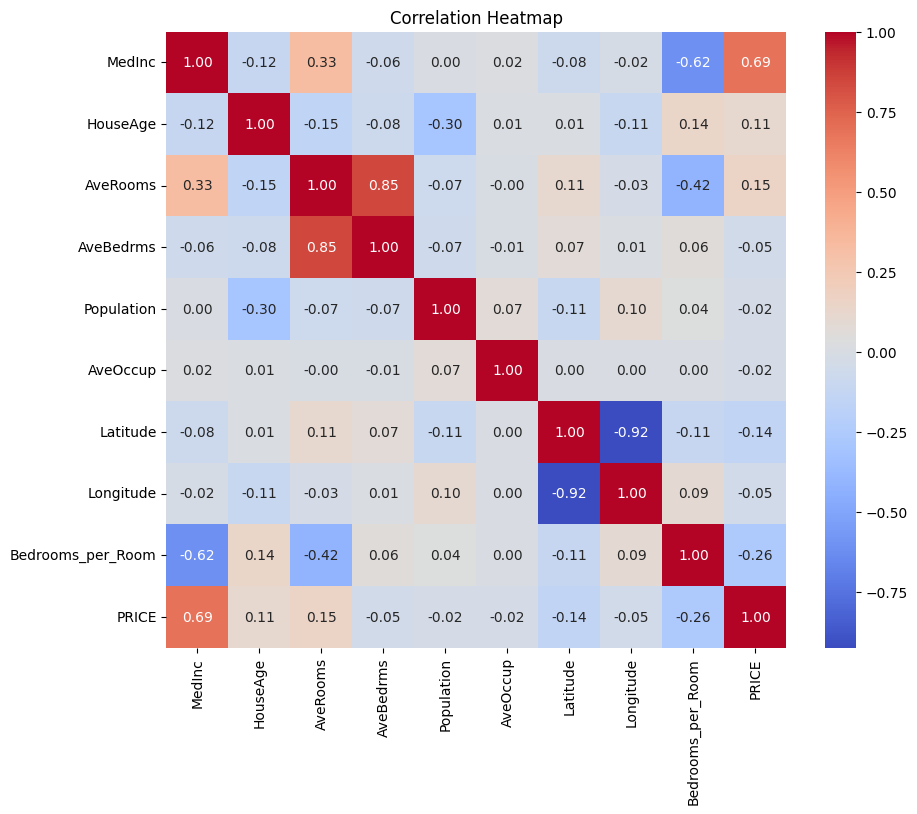

Training models and tuning hyperparameters...

Evaluating Model Deliverables...
--- OLS (Linear Regression) Metrics ---
RMSE: 0.7292 | MAE: 0.5261 | R2: 0.5942

--- Ridge (Best Alpha: 10.0) Metrics ---
RMSE: 0.7292 | MAE: 0.5260 | R2: 0.5943

--- Lasso (Best Alpha: 0.001) Metrics ---
RMSE: 0.7293 | MAE: 0.5260 | R2: 0.5941



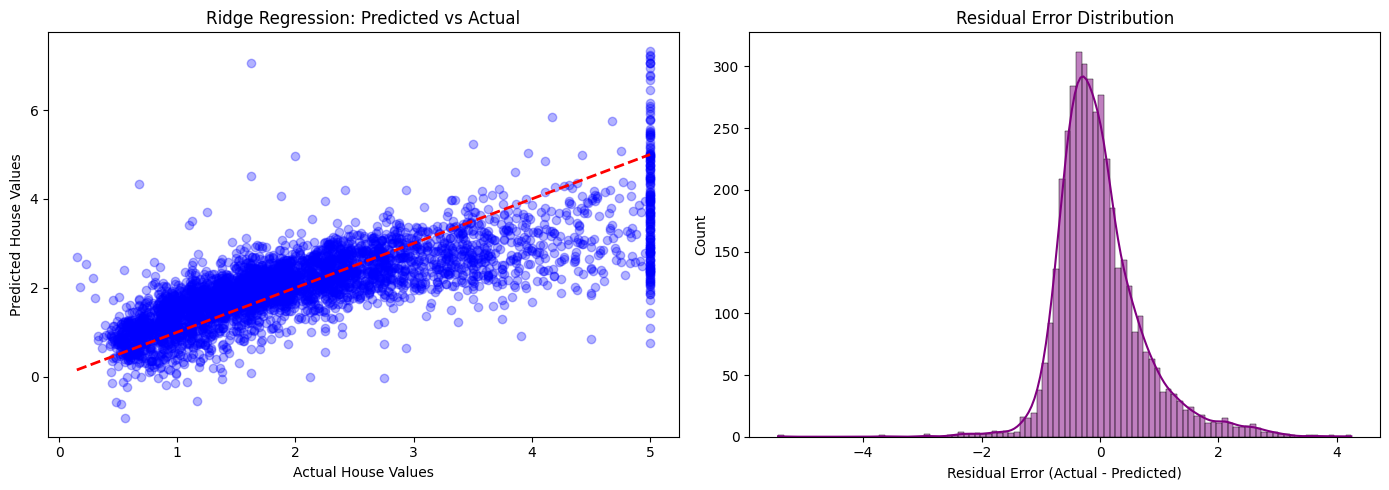

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore') # Keeps the output clean for beginners

# 1. Load California Housing Dataset
print("Loading California Housing Data...")
california = fetch_california_housing(as_frame=True)
X = california.data
y = california.target # The median house values

# 2. Feature Engineering: Create an Interaction Feature
# Combining two features to create a more insightful one
X['Bedrooms_per_Room'] = X['AveBedrms'] / X['AveRooms']

# 3. Exploratory Data Analysis: Correlation Heatmap
# Checking for multicollinearity (features that overlap too much)
plt.figure(figsize=(10, 8))
# Joining X and y temporarily just to see how features correlate with the target price
df_combined = X.copy()
df_combined['PRICE'] = y
sns.heatmap(df_combined.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# 4. Pre-processing: Split, Impute, and Standardize
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Impute any potential missing values with the median of that column
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Standardize continuous variables so they are on the same scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# 5. Train Models & Automate Hyperparameter Tuning (GridSearchCV)
print("Training models and tuning hyperparameters...")

# A. Ordinary Least Squares (Standard Linear Regression)
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

# B. Ridge Regression with GridSearchCV
ridge_params = {'alpha': [0.1, 1.0, 10.0, 100.0]}
ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=5)
ridge_grid.fit(X_train_scaled, y_train)
best_ridge = ridge_grid.best_estimator_

# C. Lasso Regression with GridSearchCV
lasso_params = {'alpha': [0.001, 0.01, 0.1, 1.0]}
lasso_grid = GridSearchCV(Lasso(), lasso_params, cv=5)
lasso_grid.fit(X_train_scaled, y_train)
best_lasso = lasso_grid.best_estimator_

# 6. Evaluate Models
def evaluate_model(name, model, X_t, y_t):
    preds = model.predict(X_t)
    rmse = np.sqrt(mean_squared_error(y_t, preds))
    mae = mean_absolute_error(y_t, preds)
    r2 = r2_score(y_t, preds)
    print(f"--- {name} Metrics ---")
    print(f"RMSE: {rmse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}\n")
    return preds

print("\nEvaluating Model Deliverables...")
ols_preds = evaluate_model("OLS (Linear Regression)", ols, X_test_scaled, y_test)
ridge_preds = evaluate_model(f"Ridge (Best Alpha: {ridge_grid.best_params_['alpha']})", best_ridge, X_test_scaled, y_test)
lasso_preds = evaluate_model(f"Lasso (Best Alpha: {lasso_grid.best_params_['alpha']})", best_lasso, X_test_scaled, y_test)

# 7. Plot Predicted vs Actual and Residual Distribution (Using Ridge as the benchmark)
residuals = y_test - ridge_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Predicted vs Actual
axes[0].scatter(y_test, ridge_preds, alpha=0.3, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # The perfect prediction line
axes[0].set_xlabel("Actual House Values")
axes[0].set_ylabel("Predicted House Values")
axes[0].set_title("Ridge Regression: Predicted vs Actual")

# Plot B: Residual Distribution Curve
sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
axes[1].set_xlabel("Residual Error (Actual - Predicted)")
axes[1].set_title("Residual Error Distribution")

plt.tight_layout()
plt.show()